# Predicción del rendimiento de trigo a partir de Sentinel-2

Estimación del rendimiento de trigo a escala de píxel (10 m) combinando series
temporales de Sentinel-2, clima, suelo y topografía, sobre el conjunto de datos
**YieldSAT** (parcelas de Alemania).

El trabajo parte de un modelo de rendimiento absoluto, diagnostica por qué sus
métricas resultan engañosas y reformula el objetivo hacia el **rendimiento
relativo intra-parcela**, que es el componente que los datos disponibles sí
permiten explicar.

| | |
|---|---|
| 1 | Configuración y parámetros |
| 2 | Funciones |
| 3 | Inventario de parcelas |
| 4 | Análisis exploratorio |
| 5 | Construcción de la tabla de variables |
| 6 | Selección de ventanas térmicas |
| 7 | Modelo de rendimiento absoluto |
| 8 | Diagnóstico de la memorización |
| 9 | Modelo relativo intra-parcela |
| 10 | Validación del modelo relativo |

## 1. Configuración y parámetros

In [1]:
import numpy as np
import pandas as pd
from scipy.stats import skew, kurtosis
import matplotlib.pyplot as plt
import os, json
import rasterio
from pysheds.grid import Grid
from scipy.ndimage import generic_filter
import xarray as xr
from xrspatial import slope, aspect, curvature

from sklearn.model_selection import train_test_split, GroupKFold, cross_val_predict
from sklearn.ensemble import RandomForestRegressor
from xgboost import XGBRegressor
from lightgbm import LGBMRegressor
from sklearn.ensemble import HistGradientBoostingRegressor
from sklearn.metrics import r2_score, mean_absolute_error, mean_squared_error
from scipy.stats import pearsonr
from sklearn.inspection import permutation_importance
from scipy.stats import spearmanr

In [ ]:
ruta = r"datos/YIELDSAT/raw/Germany"

eje_gdd = np.arange(0, 2400 + 300, 300)   # bordes de las ventanas termicas
buenas = [4, 5]                           # clases SCL validas: vegetacion y suelo

## 2. Funciones

In [3]:
def leer_tif(ruta):
    with rasterio.open(ruta) as src:
        tif= src.read(1).astype(float)
        nd=src.nodata
    if nd is not None:
        tif[tif==nd]=np.nan
    return tif

def cv_robusto(rend):
    med = np.nanmedian(rend)
    mad= np.median(np.abs(rend - med)) * 1.4826
    return mad/med


#funcion filtrado del rendimiento
def filtrar_rendimiento(ruta, parcela, sup_bio=13, inf_bio=0, umbral_sem=0.10):
    carpeta = os.path.join(ruta, parcela, "yield_masks")
    rend = leer_tif(os.path.join(carpeta, "mean_scaled_yield_masked_regional_statistical_outlier.tif"))
    num  = leer_tif(os.path.join(carpeta, "number_scaled_yield_masked_regional_statistical_outlier.tif"))
    std  = leer_tif(os.path.join(carpeta, "std_scaled_yield_masked_regional_statistical_outlier.tif"))

    rend[(rend < inf_bio) | (rend > sup_bio)] = np.nan

    with np.errstate(divide="ignore", invalid="ignore"):
        sem_rel = std / np.sqrt(num) / rend
    rend[sem_rel > umbral_sem] = np.nan

    return rend


#funcion calcular ventanas gdd

def cargar_clima(ruta, parcela, eje_gdd, t_base=0):
    """Lee el clima de la parcela, lo recorta al ciclo y calcula GDD y ventanas."""
    ruta_clima = os.path.join(ruta, parcela, "weather", parcela + ".csv")
    ruta_meta  = os.path.join(ruta, parcela, "metadata-" + parcela + ".json")

    with open(ruta_meta) as f:
        meta = json.load(f)
    siembra = pd.to_datetime(meta["seeding_date"], format="%d.%m.%Y")
    cosecha = pd.to_datetime(meta["harvesting_date"], format="%d.%m.%Y")

    clima = pd.read_csv(ruta_clima)
    clima["Date"] = pd.to_datetime(clima["Date"])
    clima = clima.sort_values("Date")
    clima = clima[(clima["Date"] >= siembra) & (clima["Date"] <= cosecha)]

    clima["Temp_max"] = clima["Temp_max"] - 273.15
    clima["Temp_min"] = clima["Temp_min"] - 273.15
    clima["grados_dia"] = (((clima["Temp_max"] + clima["Temp_min"]) / 2) - t_base).clip(lower=0)
    clima["grados_dia_acumulado"] = clima["grados_dia"].cumsum()
    clima["ventana"] = np.digitize(clima["grados_dia_acumulado"], eje_gdd)

    return clima


def calcular_indices(ruta, parcela, clima, buenas=[4, 5]):
    """Recorre las imágenes de la parcela y agrupa los índices por ventana térmica."""
    ruta_s2  = os.path.join(ruta, parcela, "s2_images")
    ruta_scl = os.path.join(ruta, parcela, "scl_masks")
    indices = {}

    for img in sorted(os.listdir(ruta_s2)):
        if not img.endswith(".tif"):
            continue
        fecha = pd.to_datetime(img.split("_")[2].replace(".tif", ""), format="%Y%m%d")

        fecha_clima = clima[clima["Date"] == fecha]
        if len(fecha_clima) == 0:
            continue
        ventana = fecha_clima["ventana"].iloc[0]

        with rasterio.open(os.path.join(ruta_s2, img)) as src:
            rojo    = src.read(4).astype(float) / 10000
            nir     = src.read(8).astype(float) / 10000
            verde   = src.read(3).astype(float) / 10000
            rededge = src.read(5).astype(float) / 10000
            swir    = src.read(11).astype(float) / 10000
            azul    = src.read(2).astype(float) / 10000

        f_scl = img.replace("S2_L2A_", "S2_L2A_SCL_")
        with rasterio.open(os.path.join(ruta_scl, f_scl)) as src:
            scl = src.read(1)
        buena = np.isin(scl, buenas)

        ivs = {
            "ndvi":  (nir - rojo) / (nir + rojo),
            "gndvi": (nir - verde) / (nir + verde),
            "ndre":  (nir - rededge) / (nir + rededge),
            "savi":  1.5 * (nir - rojo) / (nir + rojo + 0.5),
            "evi":   2.5 * (nir - rojo) / (nir + 6*rojo - 7.5*azul + 1),
            "ndwi":  (nir - swir) / (nir + swir)}

        for nombre, img_iv in ivs.items():
            img_iv[~buena] = np.nan
            indices.setdefault(nombre, {}).setdefault(ventana, []).append(img_iv)

    return indices


def hacer_compuestos(indices, es_parcela, cobertura_min=0.4):
    """Mediana por ventana, descartando las que no cubren bastante la parcela."""
    compuestos = {}
    for nombre, ventanas in indices.items():
        compuestos[nombre] = {}
        for ventana, imagenes in ventanas.items():
            comp = np.nanmedian(np.stack(imagenes), axis=0)
            cobertura = np.sum(~np.isnan(comp) & es_parcela) / np.sum(es_parcela)
            if cobertura < cobertura_min:
                comp[:] = np.nan
            compuestos[nombre][ventana] = comp
    return compuestos

def calcular_twi(ruta_dem):
    grid_dem = Grid.from_raster(ruta_dem) # coge la rejilla del dem para crearla en el formato correcto, tomando las coordenadas y el tamaño del pixel
    dem_ps = grid_dem.read_raster(ruta_dem) # mete las alturas dentro de la rejilla
    # Acondicionar el DEM para que el agua pueda fluir sin atascarse
    dem_sin_pits = grid_dem.fill_pits(dem_ps)              # rellena hoyos de 1 píxel (errores del DEM)
    dem_sin_dep = grid_dem.fill_depressions(dem_sin_pits)  # rellena hondonadas cerradas sin salida
    dem_c = grid_dem.resolve_flats(dem_sin_dep)            # da pendiente mínima a las zonas planas
    # Calcular por dónde y cuánta agua corre
    fdir = grid_dem.flowdir(dem_c, routing='mfd')          # dirección del flujo en cada píxel (MFD = reparte)
    acc = grid_dem.accumulation(fdir, routing='mfd')       # cuántos píxeles drenan hacia cada uno (área)
    acc = np.asarray(acc, dtype=float)                 # de objeto pysheds a array de numpy

    #Calcular la pendiente desde el DEM (la necesita la fórmula del TWI)
    with rasterio.open(ruta_dem) as src:
        dem = src.read(1, masked=True).astype(float).filled(np.nan)  # alturas, nodata -> NaN
        res = src.res                                               # tamaño de píxel en metros
    dy, dx = np.gradient(dem, res[1], res[0])          # gradiente (cambio de altura por metro)
    tanb = np.hypot(dx, dy)                             # tangente de la pendiente
    tanb = np.maximum(tanb, 0.001)                     # mínimo 0.001 para no dividir por 0 en lo llano
    # Fórmula: TWI = ln(area de drenaje / tangente de la pendiente)
    area = (acc + 1) * res[0]                           # area real en metros (+1 evita log(0))
    twi = np.log(area / tanb)                           # mucha agua + poca pendiente = TWI alto
    return twi

## 3. Inventario de parcelas

In [4]:
print(os.listdir(ruta))
info=[]
for carpeta in os.listdir(ruta):
    ruta_meta=os.path.join(ruta,carpeta,"metadata-"+carpeta+".json")
    with open(ruta_meta) as f:
        meta= json.load(f)
    info.append({
        "parcela": meta["field_shared_name"],
        "identificador_parcela" : meta["farm_identifier"],
        "crop": meta["crop"],
        "year": meta["year"],
        "siembra": meta["seeding_date"],
        "humedad_grano":meta["standard_moisture"],
        "cosecha": meta["harvesting_date"],
        "rendimiento": meta["yield_ground_truth"],
        "calidad_mapa": meta["yieldmap_quality"],
        "densidad": meta.get("quality_density"),
    })
informacion = pd.DataFrame(info)

['Germany_DUP3_farm1_field10_wheat_2016', 'Germany_DUP3_farm1_field11_rapeseed_2016', 'Germany_DUP3_farm1_field12_wheat_2016', 'Germany_DUP3_farm1_field13_rapeseed_2016', 'Germany_DUP3_farm1_field14_rapeseed_2016', 'Germany_DUP3_farm1_field15_rapeseed_2016', 'Germany_DUP3_farm1_field16_wheat_2016', 'Germany_DUP3_farm1_field17_wheat_2016', 'Germany_DUP3_farm1_field18_rapeseed_2016', 'Germany_DUP3_farm1_field19_rapeseed_2017', 'Germany_DUP3_farm1_field1_wheat_2016', 'Germany_DUP3_farm1_field20_rapeseed_2017', 'Germany_DUP3_farm1_field21_rapeseed_2017', 'Germany_DUP3_farm1_field22_rapeseed_2016', 'Germany_DUP3_farm1_field23_wheat_2017', 'Germany_DUP3_farm1_field24_rapeseed_2017', 'Germany_DUP3_farm1_field25_rapeseed_2017', 'Germany_DUP3_farm1_field26_wheat_2017', 'Germany_DUP3_farm1_field27_rapeseed_2017', 'Germany_DUP3_farm1_field28_wheat_2017', 'Germany_DUP3_farm1_field29_rapeseed_2017', 'Germany_DUP3_farm1_field2_wheat_2016', 'Germany_DUP3_farm1_field30_wheat_2017', 'Germany_DUP3_farm1

In [5]:
parcelas_trigo= informacion[informacion["crop"]=="wheat"]
parcelas_trigo_bien= parcelas_trigo[parcelas_trigo["calidad_mapa"].isin(["Good","Average"])]
print("nº de parcelas de trigo en el ds:",len(parcelas_trigo))
print("nº de parcelas de trigo en el ds con buena calidad:",len(parcelas_trigo_bien))

nº de parcelas de trigo en el ds: 188
nº de parcelas de trigo en el ds con buena calidad: 175


## 4. Análisis exploratorio

### 4.1 Distribución global del rendimiento

Rendimiento maximo observado: 20.0
Rendimiento minimo observado: 0.009999999776482582
Rendimiento mediano observado: 9.5649995803833
Rendimiento medio observado: 9.41305879852181
Kurtosis: 0.654335637868412
skew (asimetría): -0.2280584371051568


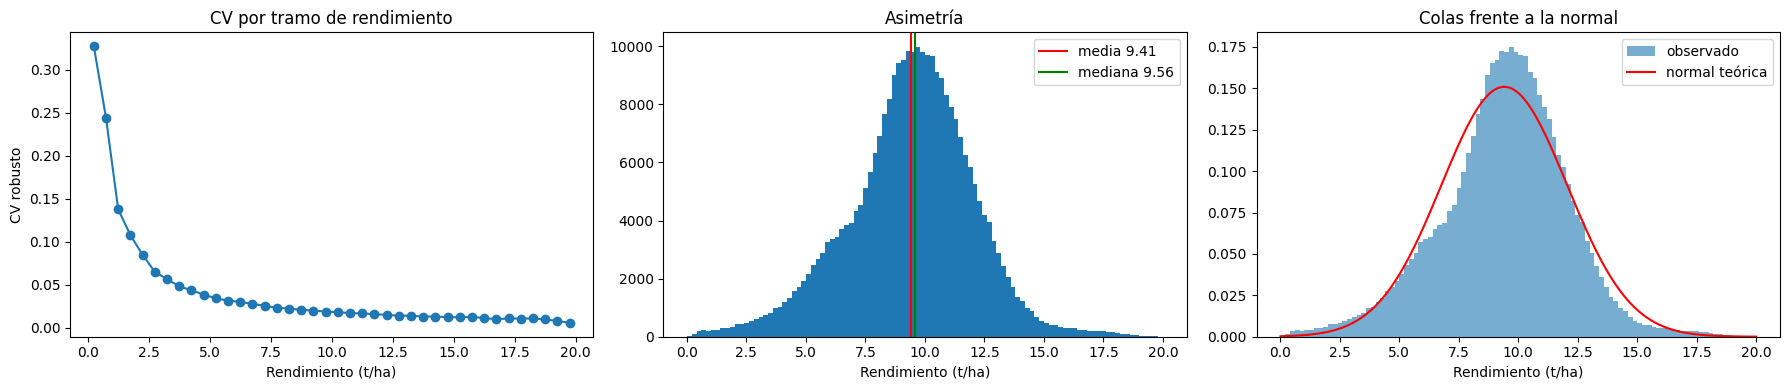

In [6]:
# 1º se va a analizar el rendimiento de las parcelas. Para ello se calcula el coeficiente de variación por tramos de rendimiento y así determinar qué píxeles son más o menos fiables. El CV es la desviación típica dividida entre
# la media, lo que da una medida de dispersión relativa al nivel de cada tramo:una desviación de 2 t/ha es mucha si la media es 5 y poca si es 15. Se usa la versión robusta (MAD/mediana) porque las distribuciones no son normales.
# Además, se va a incluir el skew (asimetria) que se calcula de la siguiente manera: media[(x-μ)³]/σ³. Al estar elevado a una potencia impar el signo de las desviaciones se mantiene, de manera que nos indica hacia cual de los lados
#, las colas de la izquierda y derecha, se concentran klos datos y con ello poder estimar si hay una cola y cual. Por otro lado, se va emplear la curtosis media[(x-μ)⁴]/σ⁴ - 3, en este caso al estar elevado a una potencia par 
# se pierde el signo  de la desviacion sumandose pero las desviaciones grandes al estar elevadas al 4 presentan un peso desproporcionado Se consideran compatibles con la normalidad valores de
# asimetría entre -0,5 y 0,5 y de curtosis entre -2 y 2; cuando ambos semantienen en ese margen, la media y la desviación típica describen bien elconjunto, y cuando no, conviene recurrir a la mediana y el IQR.
rend_todos=[]
for parcela in parcelas_trigo_bien["parcela"].tolist():
    ruta_rend= os.path.join(ruta,parcela,"yield_masks","mean_scaled_yield_masked_regional_statistical_outlier.tif" )
    rend= leer_tif(ruta_rend)
    rend= rend[~np.isnan(rend)].ravel()
    rend_todos.append(rend)

rend_todos=np.concatenate(rend_todos)
print("Rendimiento maximo observado:",np.nanmax(rend_todos))
print("Rendimiento minimo observado:",np.nanmin(rend_todos))
print("Rendimiento mediano observado:",np.nanmedian(rend_todos))
print("Rendimiento medio observado:",np.nanmean(rend_todos))
print("Kurtosis:",kurtosis(rend_todos))
print("skew (asimetría):",skew(rend_todos))
cvs = []
centros = []
tramos_rend = np.arange(0,np.nanmax(rend_todos)+0.5,0.5)
for tramo in range(len(tramos_rend)-1):
    inf =tramos_rend[tramo]
    sup =tramos_rend[tramo+1]
    masc= (rend_todos>=inf)&(rend_todos<sup)
    rend_tramo= rend_todos[masc]
    cv_tramo=cv_robusto(rend_tramo)
    cvs.append(cv_tramo)
    centros.append((inf + sup) / 2)

fig, axs = plt.subplots(1, 3, figsize=(18, 4))

# 1. CV por tramos
axs[0].plot(centros, cvs, marker="o")
axs[0].set_xlabel("Rendimiento (t/ha)")
axs[0].set_ylabel("CV robusto")
axs[0].set_title("CV por tramo de rendimiento")

# 2. histograma con media y mediana (asimetría)
axs[1].hist(rend_todos, bins=100)
axs[1].axvline(np.mean(rend_todos), color="r", label=f"media {np.mean(rend_todos):.2f}")
axs[1].axvline(np.median(rend_todos), color="g", label=f"mediana {np.median(rend_todos):.2f}")
axs[1].set_xlabel("Rendimiento (t/ha)")
axs[1].set_title("Asimetría")
axs[1].legend()

# 3. histograma vs normal teórica (curtosis)
from scipy.stats import norm
axs[2].hist(rend_todos, bins=100, density=True, alpha=0.6, label="observado")
x = np.linspace(rend_todos.min(), rend_todos.max(), 200)
axs[2].plot(x, norm.pdf(x, rend_todos.mean(), rend_todos.std()), "r-", label="normal teórica")
axs[2].set_xlabel("Rendimiento (t/ha)")
axs[2].set_title("Colas frente a la normal")
axs[2].legend()

plt.tight_layout()
plt.show()

### 4.2 Estructura a nivel de parcela

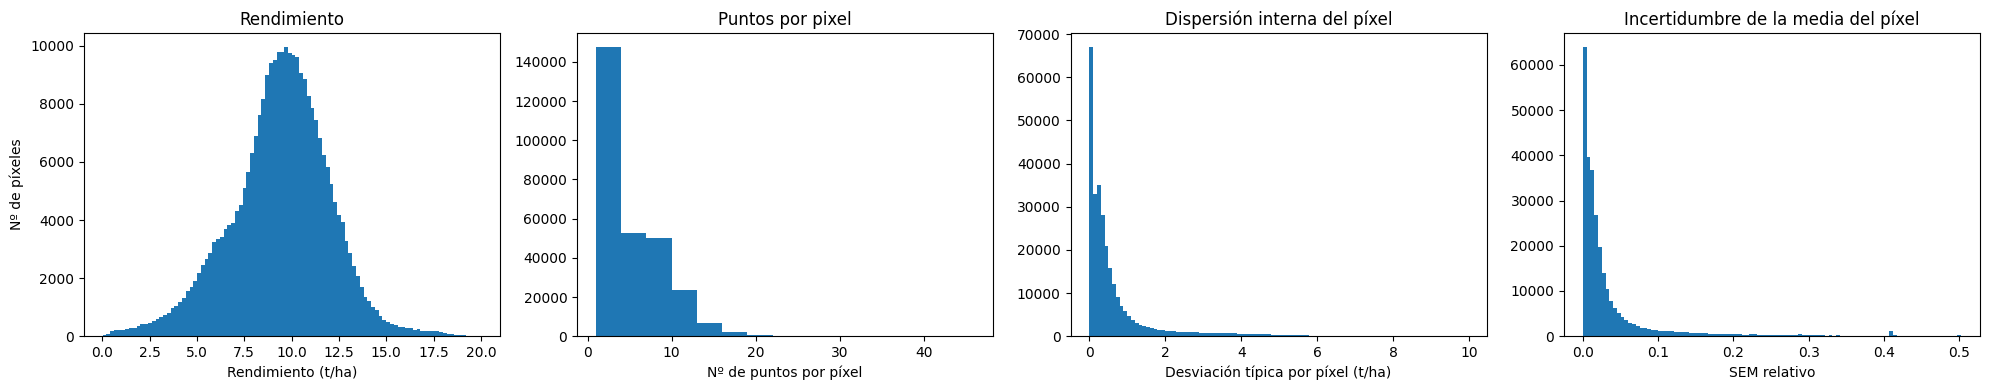

SEM relativo:
  p50: 0.015
  p75: 0.036
  p90: 0.106
  p95: 0.204
  p99: 0.502
sem_rel <= 0.05: quedan 81.2%
sem_rel <= 0.1: quedan 89.5%
sem_rel <= 0.15: quedan 92.9%
sem_rel <= 0.2: quedan 94.9%
Rango de rendimiento entre parcelas: de 5.22 a 16.60 t/ha


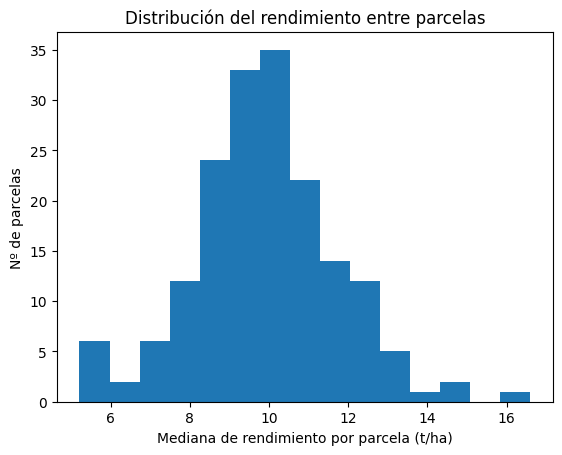

Dispersión interna de cada parcela, ordenadas de menor a mayor mediana


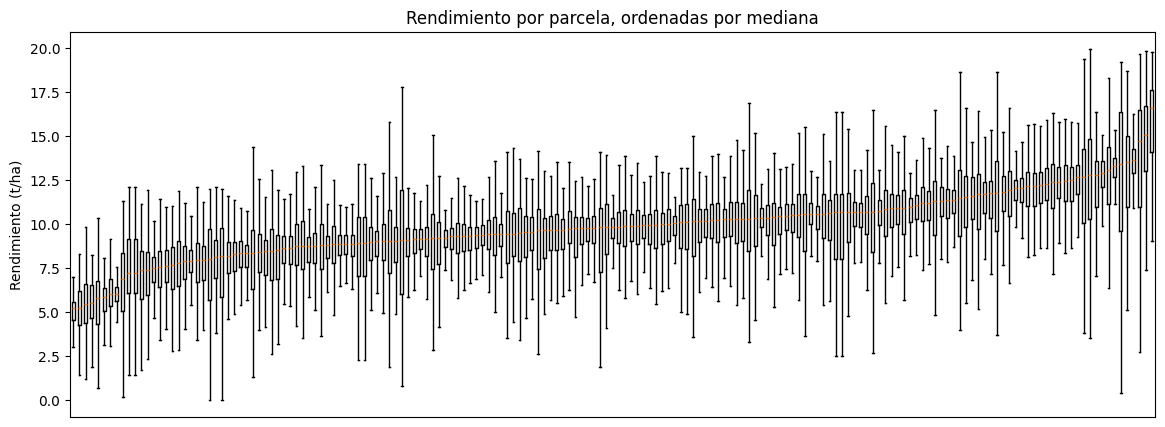

Normalidad de cada parcela: asimetría en [-0,5; 0,5] y curtosis en [-2; 2]
  cumplen ambos criterios: 12 de 175 (7%)


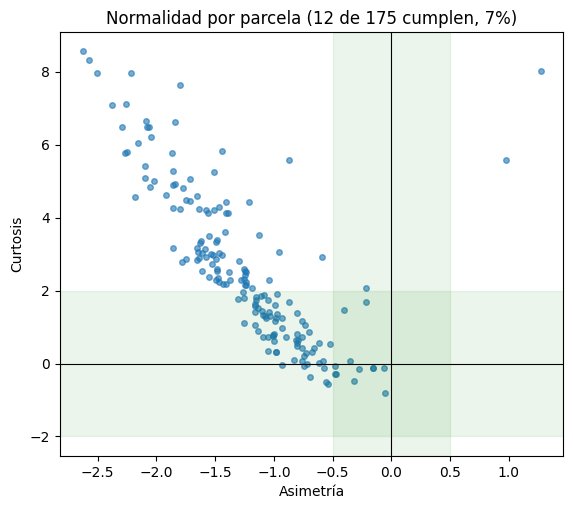

Reparto de la varianza del rendimiento:
entre parcelas: 43 %
dentro parcela: 60 %
Contraste con el rendimiento declarado en los metadatos (175 parcelas)
MEDIA   → sesgo +1.08 | R² 0.305
MEDIANA → sesgo +1.47 | R² 0.285
sesgo medio: +1.08 t/ha
R² (regresión): 0.305


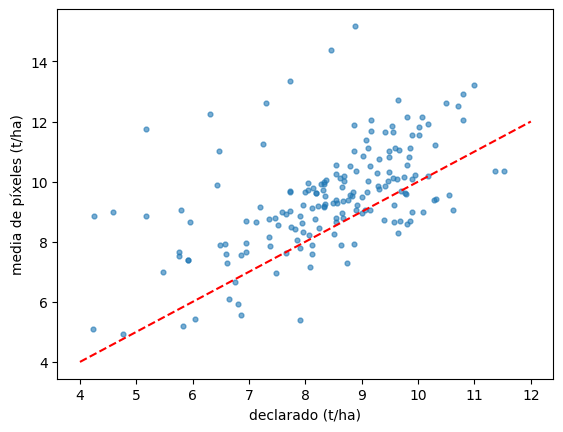

In [7]:
rend_por_parcela = {}
std_por_parcela = {}
num_por_parcela = {}
media_parcela = {}
mediana_parcela = {}
sk_parcela = {}
kurtosis_parcela = {}
var_dentro = {}

for parcela in parcelas_trigo_bien["parcela"].tolist():
    ruta_rend = os.path.join(ruta, parcela, "yield_masks", "mean_scaled_yield_masked_regional_statistical_outlier.tif")
    ruta_num  = os.path.join(ruta, parcela, "yield_masks", "number_scaled_yield_masked_regional_statistical_outlier.tif")
    ruta_std  = os.path.join(ruta, parcela, "yield_masks", "std_scaled_yield_masked_regional_statistical_outlier.tif")

    rend = leer_tif(ruta_rend)
    num  = leer_tif(ruta_num)
    std  = leer_tif(ruta_std)

    ok = ~np.isnan(rend) & ~np.isnan(num) & ~np.isnan(std)

    rend_por_parcela[parcela] = rend[ok]
    num_por_parcela[parcela]  = num[ok]
    std_por_parcela[parcela]  = std[ok]

for nombre,rend in rend_por_parcela.items():
    var_par = np.var(rend)
    var_dentro[nombre]=var_par
    media_par = np.nanmean(rend)
    media_parcela[nombre]= media_par
    mediana_par = np.nanmedian(rend)
    mediana_parcela[nombre]= mediana_par
    kurt_par= kurtosis(rend)
    sk_par= skew(rend)
    sk_parcela[nombre]= sk_par
    kurtosis_parcela[nombre]=kurt_par

todos_rend = np.concatenate(list(rend_por_parcela.values()))
todos_num  = np.concatenate(list(num_por_parcela.values()))
todos_std  = np.concatenate(list(std_por_parcela.values()))
sem_rel = todos_std / np.sqrt(todos_num) / todos_rend

fig, axs = plt.subplots(1, 4, figsize=(20, 4))

axs[0].hist(todos_rend, bins=100)
axs[0].set_xlabel("Rendimiento (t/ha)")
axs[0].set_ylabel("Nº de píxeles")
axs[0].set_title("Rendimiento")

axs[1].hist(todos_num, bins=15)
axs[1].set_xlabel("Nº de puntos por píxel")
axs[1].set_title("Puntos por pixel")

axs[2].hist(todos_std, bins=100)
axs[2].set_xlabel("Desviación típica por píxel (t/ha)")
axs[2].set_title("Dispersión interna del píxel")

axs[3].hist(sem_rel, bins=100, range=(0, np.percentile(sem_rel, 99)))
axs[3].set_xlabel("SEM relativo")
axs[3].set_title("Incertidumbre de la media del píxel")

plt.tight_layout()
plt.show()
print("SEM relativo:")
for p in [50, 75, 90, 95, 99]:
    print(f"  p{p}: {np.percentile(sem_rel, p):.3f}")

for u in [0.05, 0.1, 0.15, 0.2]:
    print(f"sem_rel <= {u}: quedan {100*(sem_rel <= u).mean():.1f}%")
print("Rango de rendimiento entre parcelas: de",
      f"{min(mediana_parcela.values()):.2f} a {max(mediana_parcela.values()):.2f} t/ha")
plt.hist(list(mediana_parcela.values()), bins=15)
plt.xlabel("Mediana de rendimiento por parcela (t/ha)")
plt.ylabel("Nº de parcelas")
plt.title("Distribución del rendimiento entre parcelas")
plt.show()
orden = sorted(rend_por_parcela, key=lambda p: np.median(rend_por_parcela[p]))

print("Dispersión interna de cada parcela, ordenadas de menor a mayor mediana")
plt.figure(figsize=(14, 5))
plt.boxplot([rend_por_parcela[p] for p in orden], showfliers=False)
plt.xticks([])          # quito las etiquetas, son 175 nombres larguísimos
plt.ylabel("Rendimiento (t/ha)")
plt.title("Rendimiento por parcela, ordenadas por mediana")
plt.show()

skews = np.array(list(sk_parcela.values()))
kurts = np.array(list(kurtosis_parcela.values()))
normal = (np.abs(skews) <= 0.5) & (np.abs(kurts) <= 2)

print("Normalidad de cada parcela: asimetría en [-0,5; 0,5] y curtosis en [-2; 2]")
print(f"  cumplen ambos criterios: {normal.sum()} de {len(skews)} ({100*normal.mean():.0f}%)")
plt.figure(figsize=(6.5, 5.5))
plt.scatter(skews, kurts, s=16, alpha=0.6)
plt.axvspan(-0.5, 0.5, color="green", alpha=0.08)
plt.axhspan(-2, 2, color="green", alpha=0.08)
plt.axvline(0, color="k", lw=0.8)
plt.axhline(0, color="k", lw=0.8)
plt.xlabel("Asimetría")
plt.ylabel("Curtosis")
plt.title(f"Normalidad por parcela ({normal.sum()} de {len(skews)} cumplen, {100*normal.mean():.0f}%)")
plt.show()
# DESCOMPOSICIÓN DE LA VARIANZA
#
# Se separa la variabilidad del rendimiento en dos componentes: entre parcelas
# (unos campos rinden más que otros) y dentro de cada parcela (variación
# espacial interna). El reparto indica qué parte es abordable: la variación
# entre campos depende de variedad y manejo, ausentes del dataset, mientras que
# la interna sí la recogen las imágenes de satélite.
var_dentro_media = np.mean(list(var_dentro.values()))
var_entre = np.var(list(media_parcela.values()))
todos = np.concatenate(list(rend_por_parcela.values()))
var_total = np.var(todos)

print("Reparto de la varianza del rendimiento:")
print("entre parcelas:", round(100*var_entre/var_total), "%")
print("dentro parcela:", round(100*var_dentro_media/var_total), "%")


dec = pd.to_numeric(parcelas_trigo_bien.set_index("parcela")["rendimiento"],
                    errors="coerce")
pix = pd.Series(media_parcela)
j = pd.concat([pix.rename("pixeles"), dec.rename("declarado")], axis=1).dropna()
# R² de la regresión lineal 
r2_reg = j["pixeles"].corr(j["declarado"])**2
pix_med = pd.Series(mediana_parcela)
j2 = pd.concat([pix_med.rename("pixeles_med"), dec.rename("declarado")], axis=1).dropna()

print(f"Contraste con el rendimiento declarado en los metadatos ({len(j)} parcelas)")
print(f"MEDIA   → sesgo {(j['pixeles']-j['declarado']).mean():+.2f} | R² {j['pixeles'].corr(j['declarado'])**2:.3f}")
print(f"MEDIANA → sesgo {(j2['pixeles_med']-j2['declarado']).mean():+.2f} | R² {j2['pixeles_med'].corr(j2['declarado'])**2:.3f}")
print(f"sesgo medio: {(j['pixeles']-j['declarado']).mean():+.2f} t/ha")
print(f"R² (regresión): {r2_reg:.3f}")
plt.scatter(j["declarado"], j["pixeles"], s=12, alpha=0.6)
plt.plot([4,12],[4,12],"r--")
plt.xlabel("declarado (t/ha)"); plt.ylabel("media de píxeles (t/ha)")
plt.show()

### 4.3 Caracterización térmica del ciclo del cultivo

In [8]:
clima_por_parcela = {}
ndvi_por_parcela = {}
compuestos_todo = {}

for parcela in parcelas_trigo_bien["parcela"].tolist():
    ruta_meta  = os.path.join(ruta, parcela, "metadata-"+parcela+".json")
    ruta_clima = os.path.join(ruta, parcela, "weather", parcela+".csv")
    ruta_s2    = os.path.join(ruta, parcela, "s2_images")
    ruta_scl   = os.path.join(ruta, parcela, "scl_masks")
    ruta_rend  = os.path.join(ruta, parcela, "yield_masks",
                              "mean_scaled_yield_masked_regional_statistical_outlier.tif")

    with open(ruta_meta) as f:
        meta = json.load(f)
    siembra = pd.to_datetime(meta["seeding_date"], format="%d.%m.%Y")
    cosecha = pd.to_datetime(meta["harvesting_date"], format="%d.%m.%Y")

    clima = pd.read_csv(ruta_clima)
    clima["Temp_mean"] = clima["Temp_mean"] - 273.15
    clima["Temp_max"]  = clima["Temp_max"] - 273.15
    clima["Temp_min"]  = clima["Temp_min"] - 273.15
    clima["Date"] = pd.to_datetime(clima["Date"])
    clima = clima.sort_values("Date")
    clima = clima[(clima["Date"] >= siembra) & (clima["Date"] <= cosecha)]

    clima["grados_dia"] = (((clima["Temp_max"]+clima["Temp_min"])/2) - 0).clip(lower=0)
    clima["grados_dia_acumulado"] = clima["grados_dia"].cumsum()
    clima["ventana"] = np.digitize(clima["grados_dia_acumulado"], eje_gdd)

    indices = {}
    filas = []

    for img in sorted(os.listdir(ruta_s2)):
        if not img.endswith(".tif"):
            continue
        fecha = pd.to_datetime(img.split("_")[2].replace(".tif", ""), format="%Y%m%d")

        fecha_clima = clima[clima["Date"] == fecha]
        if len(fecha_clima) == 0:
            continue                                    # imagen fuera del ciclo
        ventana = fecha_clima["ventana"].iloc[0]

        with rasterio.open(os.path.join(ruta_s2, img)) as src:
            rojo    = src.read(4).astype(float) / 10000
            nir     = src.read(8).astype(float) / 10000
            verde   = src.read(3).astype(float) / 10000
            rededge = src.read(5).astype(float) / 10000
            swir    = src.read(11).astype(float) / 10000
            azul    = src.read(2).astype(float) / 10000
            perfil_s2 = src.profile

        f_scl = img.replace("S2_L2A_", "S2_L2A_SCL_")
        with rasterio.open(os.path.join(ruta_scl, f_scl)) as src:
            scl = src.read(1)
        buena = np.isin(scl, buenas)

        ndvi  = (nir - rojo) / (nir + rojo)
        gndvi = (nir - verde) / (nir + verde)
        ndre  = (nir - rededge) / (nir + rededge)
        savi  = 1.5 * (nir - rojo) / (nir + rojo + 0.5)
        evi   = 2.5 * (nir - rojo) / (nir + 6*rojo - 7.5*azul + 1)
        ndwi  = (nir - swir) / (nir + swir)

        ivs_cal = {"ndvi": ndvi, "gndvi": gndvi, "ndre": ndre,
                   "savi": savi, "evi": evi, "ndwi": ndwi}

        for nombre, img_iv in ivs_cal.items():
            img_iv[~buena] = np.nan
            if nombre not in indices:
                indices[nombre] = {}
            if ventana not in indices[nombre]:
                indices[nombre][ventana] = []
            indices[nombre][ventana].append(img_iv)

        # serie de NDVI medio, solo si la imagen tiene cobertura suficiente
        if np.mean(~np.isnan(ndvi)) >= 0.3:
            filas.append({"fecha": fecha,
                          "gdd": fecha_clima["grados_dia_acumulado"].iloc[0],
                          "ndvi": np.nanmean(ndvi)})

    clima_por_parcela[parcela] = clima
    if filas:
        ndvi_por_parcela[parcela] = pd.DataFrame(filas)

    # compuestos por ventana
    rend2d = leer_tif(ruta_rend)
    es_parcela = ~np.isnan(rend2d)

    compuestos_por_parcela = {}
    for nombre, ventanas in indices.items():
        compuestos_por_parcela[nombre] = {}
        for ventana, imagenes in ventanas.items():
            compuesto = np.nanmedian(np.stack(imagenes), axis=0)
            con_dato = ~np.isnan(compuesto) & es_parcela
            compuestos_por_parcela[nombre][ventana] = compuesto

    compuestos_todo[parcela] = compuestos_por_parcela
    print(f"{parcela}: {len(filas)} imágenes, ventanas con compuesto: {sorted(compuestos_por_parcela['ndvi'].keys())}")

print(f"Parcelas procesadas: {len(compuestos_todo)}")

C:\Users\34695\AppData\Local\Temp\ipykernel_28720\1757636241.py:61: RuntimeWarning: divide by zero encountered in divide
  evi   = 2.5 * (nir - rojo) / (nir + 6*rojo - 7.5*azul + 1)
C:\Users\34695\AppData\Local\Temp\ipykernel_28720\1757636241.py:93: RuntimeWarning: All-NaN slice encountered
  compuesto = np.nanmedian(np.stack(imagenes), axis=0)


Germany_DUP3_farm1_field12_wheat_2016: 10 imágenes, ventanas con compuesto: [1, 2, 3, 4, 5, 6, 7, 8, 9]


C:\Users\34695\AppData\Local\Temp\ipykernel_28720\1757636241.py:61: RuntimeWarning: divide by zero encountered in divide
  evi   = 2.5 * (nir - rojo) / (nir + 6*rojo - 7.5*azul + 1)
C:\Users\34695\AppData\Local\Temp\ipykernel_28720\1757636241.py:93: RuntimeWarning: All-NaN slice encountered
  compuesto = np.nanmedian(np.stack(imagenes), axis=0)


Germany_DUP3_farm1_field16_wheat_2016: 9 imágenes, ventanas con compuesto: [1, 2, 3, 4, 5, 6, 7, 8, 9]


C:\Users\34695\AppData\Local\Temp\ipykernel_28720\1757636241.py:93: RuntimeWarning: All-NaN slice encountered
  compuesto = np.nanmedian(np.stack(imagenes), axis=0)


Germany_DUP3_farm1_field17_wheat_2016: 8 imágenes, ventanas con compuesto: [1, 2, 3, 4, 5, 6, 7, 8, 9]


... (339 outputs left out)

Germany_DUP3_farm6_field287_wheat_2016: 6 imágenes, ventanas con compuesto: [2, 3, 4, 5, 6, 7, 8, 9]


C:\Users\34695\AppData\Local\Temp\ipykernel_28720\1757636241.py:61: RuntimeWarning: divide by zero encountered in divide
  evi   = 2.5 * (nir - rojo) / (nir + 6*rojo - 7.5*azul + 1)
C:\Users\34695\AppData\Local\Temp\ipykernel_28720\1757636241.py:93: RuntimeWarning: All-NaN slice encountered
  compuesto = np.nanmedian(np.stack(imagenes), axis=0)
C:\Users\34695\AppData\Local\Temp\ipykernel_28720\1757636241.py:61: RuntimeWarning: divide by zero encountered in divide
  evi   = 2.5 * (nir - rojo) / (nir + 6*rojo - 7.5*azul + 1)


Germany_DUP3_farm6_field289_wheat_2021: 20 imágenes, ventanas con compuesto: [1, 2, 3, 4, 5, 6, 7, 8, 9]
Germany_DUP3_farm6_field295_wheat_2017: 10 imágenes, ventanas con compuesto: [1, 2, 3, 4, 5, 6, 7, 8]
Parcelas procesadas: 175


C:\Users\34695\AppData\Local\Temp\ipykernel_28720\1757636241.py:93: RuntimeWarning: All-NaN slice encountered
  compuesto = np.nanmedian(np.stack(imagenes), axis=0)


Parcelas con clima: 175 | con NDVI: 174
NDVI acumulado al final del ciclo (mediana): 1449 NDVI·GDD


C:\Users\34695\AppData\Local\Temp\ipykernel_28720\186977011.py:92: MatplotlibDeprecationWarning: The 'labels' parameter of boxplot() has been renamed 'tick_labels' since Matplotlib 3.9; support for the old name will be dropped in 3.11.
  axs[1,0].boxplot([tot[a] for a in anios], labels=anios)


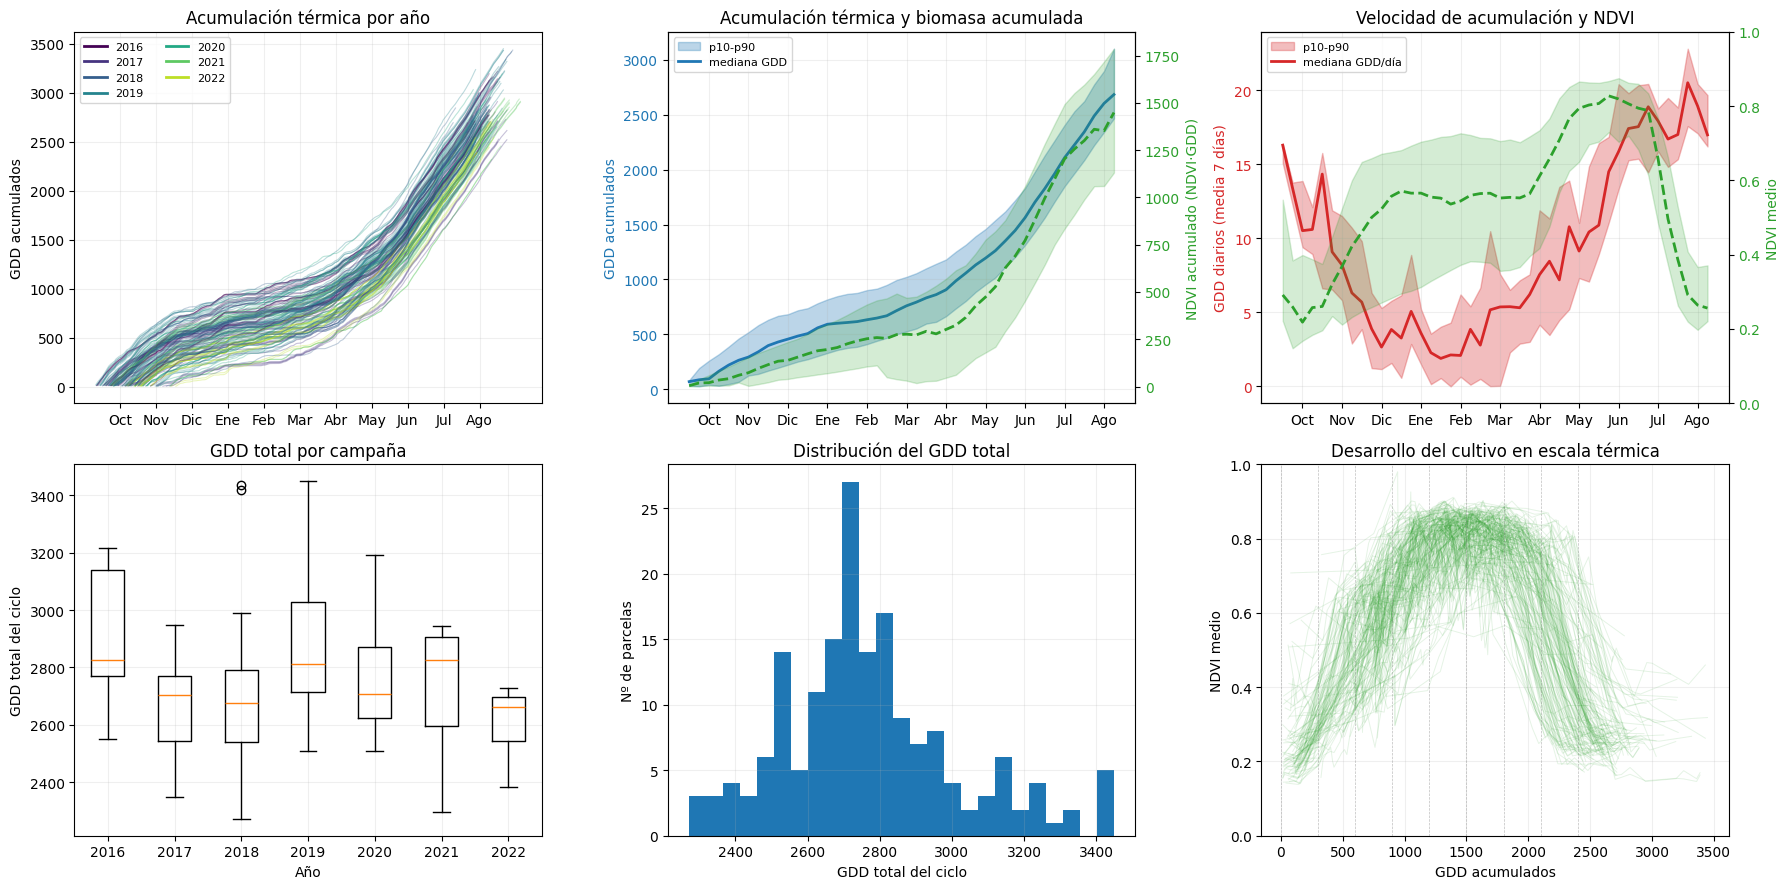

In [9]:
rejilla = np.arange(9.5, 20.5, 0.25)
etiquetas = ["Oct","Nov","Dic","Ene","Feb","Mar","Abr","May","Jun","Jul","Ago"]
anios = sorted({p.split("_")[-1] for p in clima_por_parcela})
colores = dict(zip(anios, plt.cm.viridis(np.linspace(0, 0.9, len(anios)))))

def eje_mes(fechas, anio_siembra):
    mes = fechas.dt.month + fechas.dt.day / 30.44
    return mes + (fechas.dt.year > anio_siembra) * 12

# --- NDVI acumulado: integral por trapecios respecto al GDD ---
for parcela, s in ndvi_por_parcela.items():
    s = s.sort_values("gdd").reset_index(drop=True)
    ndvi = s["ndvi"].to_numpy()
    gdd = s["gdd"].to_numpy()
    areas = (ndvi[:-1] + ndvi[1:]) / 2 * np.diff(gdd)
    s["ndvi_acum"] = np.concatenate([[0], np.cumsum(areas)])
    ndvi_por_parcela[parcela] = s

# --- curvas típicas interpoladas a la rejilla común ---
acum, vel, ndvis, nacum = [], [], [], []
for parcela, cl in clima_por_parcela.items():
    anio_s = cl["Date"].iloc[0].year
    m = eje_mes(cl["Date"], anio_s)
    acum.append(np.interp(rejilla, m, cl["grados_dia_acumulado"], left=np.nan, right=np.nan))
    vel.append(np.interp(rejilla, m, cl["grados_dia"].rolling(7, center=True).mean(),
                         left=np.nan, right=np.nan))
    if parcela in ndvi_por_parcela:
        s = ndvi_por_parcela[parcela]
        mn = eje_mes(s["fecha"], anio_s).to_numpy()
        o = np.argsort(mn)
        ndvis.append(np.interp(rejilla, mn[o], s["ndvi"].to_numpy()[o],
                               left=np.nan, right=np.nan))
        nacum.append(np.interp(rejilla, mn[o], s["ndvi_acum"].to_numpy()[o],
                               left=np.nan, right=np.nan))

acum, vel = np.array(acum), np.array(vel)
ndvis, nacum = np.array(ndvis), np.array(nacum)
p10, p50, p90 = (np.nanpercentile(acum, q, axis=0) for q in (10, 50, 90))
v10, v50, v90 = (np.nanpercentile(vel, q, axis=0) for q in (10, 50, 90))
n10, n50, n90 = (np.nanpercentile(ndvis, q, axis=0) for q in (10, 50, 90))
a10, a50, a90 = (np.nanpercentile(nacum, q, axis=0) for q in (10, 50, 90))

print(f"Parcelas con clima: {len(clima_por_parcela)} | con NDVI: {len(ndvi_por_parcela)}")
print(f"NDVI acumulado al final del ciclo (mediana): {np.nanmedian(nacum[:, -1]):.0f} NDVI·GDD")

fig, axs = plt.subplots(2, 3, figsize=(18, 9))

# --- 1. acumulación térmica por año ---
for parcela, cl in clima_por_parcela.items():
    axs[0,0].plot(eje_mes(cl["Date"], cl["Date"].iloc[0].year),
                  cl["grados_dia_acumulado"],
                  alpha=0.3, lw=0.8, color=colores[parcela.split("_")[-1]])
for a in anios:
    axs[0,0].plot([], [], color=colores[a], lw=2, label=a)
axs[0,0].set_ylabel("GDD acumulados")
axs[0,0].set_title("Acumulación térmica por año")
axs[0,0].legend(fontsize=8, ncol=2)

# --- 2. GDD acumulado + NDVI acumulado ---
axs[0,1].fill_between(rejilla, p10, p90, alpha=0.3, color="tab:blue", label="p10-p90")
axs[0,1].plot(rejilla, p50, color="tab:blue", lw=2, label="mediana GDD")
axs[0,1].set_ylabel("GDD acumulados", color="tab:blue")
axs[0,1].tick_params(axis="y", labelcolor="tab:blue")
axs[0,1].set_title("Acumulación térmica y biomasa acumulada")
axs[0,1].legend(loc="upper left", fontsize=8)

ax2b = axs[0,1].twinx()
ax2b.fill_between(rejilla, a10, a90, alpha=0.2, color="tab:green")
ax2b.plot(rejilla, a50, color="tab:green", lw=2, ls="--")
ax2b.set_ylabel("NDVI acumulado (NDVI·GDD)", color="tab:green")
ax2b.tick_params(axis="y", labelcolor="tab:green")

# --- 3. velocidad de acumulación + NDVI ---
axs[0,2].fill_between(rejilla, v10, v90, alpha=0.3, color="tab:red", label="p10-p90")
axs[0,2].plot(rejilla, v50, color="tab:red", lw=2, label="mediana GDD/día")
axs[0,2].set_ylabel("GDD diarios (media 7 días)", color="tab:red")
axs[0,2].tick_params(axis="y", labelcolor="tab:red")
axs[0,2].set_title("Velocidad de acumulación y NDVI")
axs[0,2].legend(loc="upper left", fontsize=8)

ax3b = axs[0,2].twinx()
ax3b.fill_between(rejilla, n10, n90, alpha=0.2, color="tab:green")
ax3b.plot(rejilla, n50, color="tab:green", lw=2, ls="--")
ax3b.set_ylabel("NDVI medio", color="tab:green")
ax3b.tick_params(axis="y", labelcolor="tab:green")
ax3b.set_ylim(0, 1)

# --- 4. GDD total por campaña ---
tot = {a: [] for a in anios}
for parcela, cl in clima_por_parcela.items():
    tot[parcela.split("_")[-1]].append(cl["grados_dia_acumulado"].iloc[-1])
axs[1,0].boxplot([tot[a] for a in anios], labels=anios)
axs[1,0].set_ylabel("GDD total del ciclo"); axs[1,0].set_xlabel("Año")
axs[1,0].set_title("GDD total por campaña")

# --- 5. histograma del GDD total ---
axs[1,1].hist([cl["grados_dia_acumulado"].iloc[-1] for cl in clima_por_parcela.values()],
              bins=25)
axs[1,1].set_xlabel("GDD total del ciclo"); axs[1,1].set_ylabel("Nº de parcelas")
axs[1,1].set_title("Distribución del GDD total")

# --- 6. NDVI frente a GDD (escala térmica) ---
for parcela, s in ndvi_por_parcela.items():
    axs[1,2].plot(s["gdd"], s["ndvi"], alpha=0.12, lw=0.7, color="tab:green")
for b in eje_gdd:
    axs[1,2].axvline(b, color="gray", ls="--", lw=0.5, alpha=0.5)
axs[1,2].set_xlabel("GDD acumulados"); axs[1,2].set_ylabel("NDVI medio")
axs[1,2].set_ylim(0, 1)
axs[1,2].set_title("Desarrollo del cultivo en escala térmica")

for a in [axs[0,0], axs[0,1], axs[0,2]]:
    a.set_xticks(range(10, 21)); a.set_xticklabels(etiquetas)
for a in axs.ravel():
    a.grid(alpha=0.2)
plt.tight_layout(); plt.show()

## 5. Construcción de la tabla de variables

In [10]:
tablas = []

for parcela in parcelas_trigo_bien["parcela"].tolist():
    rend = filtrar_rendimiento(ruta, parcela)          # el que va a la tabla

    ruta_rend = os.path.join(ruta, parcela, "yield_masks",
                             "mean_scaled_yield_masked_regional_statistical_outlier.tif")
    es_parcela = ~np.isnan(leer_tif(ruta_rend))        # molde sin filtrar

    clima = cargar_clima(ruta, parcela, eje_gdd)
    indices = calcular_indices(ruta, parcela, clima)
    compuestos = hacer_compuestos(indices, es_parcela)

    # --- cruce pixel a pixel ---
    filas_idx, cols_idx = np.indices(rend.shape)
    tabla = {
        "parcela": parcela,
        "fila": filas_idx.ravel(),
        "col": cols_idx.ravel(),
        "rendimiento": rend.ravel()}

    for nombre, ventanas in compuestos.items():
        for v, comp in ventanas.items():
            tabla[f"{nombre}_v{v}"] = comp.ravel()
    agg = clima.groupby("ventana").agg(
        tmax=("Temp_max", "mean"),
        tmin=("Temp_min", "mean"),
        prec=("Total_prec", "sum"),
        dias=("Date", "count"))
    agg["prec"] = agg["prec"] * 1000
    agg["tmed"] = (agg["tmax"] + agg["tmin"]) / 2

    for v, fila in agg.iterrows():
        for col in ["tmax", "tmin", "tmed", "prec", "dias"]:
            tabla[f"{col}_v{v}"] = fila[col]

    dem = leer_tif(os.path.join(ruta, parcela, "dem", "dem-" + parcela + ".tif"))
    dy, dx = np.gradient(dem, 10)              # 10 m de píxel
    # curvatura: derivada segunda de la elevación
    dyy = np.gradient(dy, 10, axis=0)
    dxx = np.gradient(dx, 10, axis=1)
    curvatura = -(dxx + dyy)      # positiva = convexo (loma), negativa = cóncavo (vaguada)
    pendiente = np.degrees(np.arctan(np.sqrt(dx**2 + dy**2)))
    orientacion = np.degrees(np.arctan2(-dx, dy)) % 360
    tabla["dem"] = dem.ravel()
    tabla["pendiente"] = pendiente.ravel()
    tabla["orient_sur"] = np.cos(np.radians(orientacion - 180)).ravel()
    tabla["curvatura"] = curvatura.ravel()
    tabla["twi_propio"] = calcular_twi(os.path.join(ruta, parcela, "dem", "dem-" + parcela + ".tif")).ravel()

    tabla = pd.DataFrame(tabla)
    tabla = tabla[~tabla["rendimiento"].isna()]        # solo píxeles con rendimiento
    tablas.append(tabla)
    print(f"{parcela}: {len(tabla)} píxeles")

datos = pd.concat(tablas, ignore_index=True)
print(f"Tabla final: {len(datos)} píxeles, {datos.shape[1]} columnas")
print(f"Parcelas: {datos['parcela'].nunique()}")

C:\Users\34695\AppData\Local\Temp\ipykernel_28720\2351328466.py:91: RuntimeWarning: divide by zero encountered in divide
  "evi":   2.5 * (nir - rojo) / (nir + 6*rojo - 7.5*azul + 1),
C:\Users\34695\AppData\Local\Temp\ipykernel_28720\2351328466.py:107: RuntimeWarning: All-NaN slice encountered
  comp = np.nanmedian(np.stack(imagenes), axis=0)


Germany_DUP3_farm1_field12_wheat_2016: 890 píxeles


C:\Users\34695\AppData\Local\Temp\ipykernel_28720\2351328466.py:91: RuntimeWarning: divide by zero encountered in divide
  "evi":   2.5 * (nir - rojo) / (nir + 6*rojo - 7.5*azul + 1),
C:\Users\34695\AppData\Local\Temp\ipykernel_28720\2351328466.py:107: RuntimeWarning: All-NaN slice encountered
  comp = np.nanmedian(np.stack(imagenes), axis=0)


Germany_DUP3_farm1_field16_wheat_2016: 812 píxeles


C:\Users\34695\AppData\Local\Temp\ipykernel_28720\2351328466.py:107: RuntimeWarning: All-NaN slice encountered
  comp = np.nanmedian(np.stack(imagenes), axis=0)
C:\Users\34695\AppData\Local\Temp\ipykernel_28720\2351328466.py:91: RuntimeWarning: divide by zero encountered in divide
  "evi":   2.5 * (nir - rojo) / (nir + 6*rojo - 7.5*azul + 1),
C:\Users\34695\AppData\Local\Temp\ipykernel_28720\2351328466.py:87: RuntimeWarning: invalid value encountered in divide
  "ndvi":  (nir - rojo) / (nir + rojo),
C:\Users\34695\AppData\Local\Temp\ipykernel_28720\2351328466.py:88: RuntimeWarning: invalid value encountered in divide
  "gndvi": (nir - verde) / (nir + verde),


Germany_DUP3_farm1_field17_wheat_2016: 745 píxeles


... (335 outputs left out)

Germany_DUP3_farm6_field287_wheat_2016: 2817 píxeles


C:\Users\34695\AppData\Local\Temp\ipykernel_28720\2351328466.py:91: RuntimeWarning: divide by zero encountered in divide
  "evi":   2.5 * (nir - rojo) / (nir + 6*rojo - 7.5*azul + 1),
C:\Users\34695\AppData\Local\Temp\ipykernel_28720\2351328466.py:107: RuntimeWarning: All-NaN slice encountered
  comp = np.nanmedian(np.stack(imagenes), axis=0)
C:\Users\34695\AppData\Local\Temp\ipykernel_28720\2351328466.py:91: RuntimeWarning: divide by zero encountered in divide
  "evi":   2.5 * (nir - rojo) / (nir + 6*rojo - 7.5*azul + 1),


Germany_DUP3_farm6_field289_wheat_2021: 1203 píxeles
Germany_DUP3_farm6_field295_wheat_2017: 2052 píxeles
Tabla final: 236310 píxeles, 108 columnas
Parcelas: 175


C:\Users\34695\AppData\Local\Temp\ipykernel_28720\2351328466.py:107: RuntimeWarning: All-NaN slice encountered
  comp = np.nanmedian(np.stack(imagenes), axis=0)


## 6. Selección de ventanas 


In [11]:
print(datos.isna().sum().to_string())

for fuera in [("_v1","_v2"), ("_v1","_v2","_v9"), ("_v1","_v2","_v8","_v9"), ("_v9",)]:
    sub = datos.drop(columns=[c for c in datos.columns if c.endswith(fuera)]).dropna()
    print(f"sin {fuera}: {sub['parcela'].nunique()} parcelas, {len(sub)} píxeles")

parcela            0
fila               0
col                0
rendimiento        0
ndvi_v1        87203
ndvi_v2        92295
ndvi_v3        33264
ndvi_v4        22404
ndvi_v5         9680
ndvi_v6        24266
ndvi_v7        42427
ndvi_v8        47656
ndvi_v9        37946
gndvi_v1       87203
gndvi_v2       92295
gndvi_v3       33264
gndvi_v4       22404
gndvi_v5        9680
gndvi_v6       24266
gndvi_v7       42427
gndvi_v8       47656
gndvi_v9       37946
ndre_v1        87203
ndre_v2        92295
ndre_v3        33264
ndre_v4        22404
ndre_v5         9680
ndre_v6        24266
ndre_v7        42427
ndre_v8        47656
ndre_v9        37946
savi_v1        87203
savi_v2        92295
savi_v3        33264
savi_v4        22404
savi_v5         9680
savi_v6        24266
savi_v7        42427
savi_v8        47656
savi_v9        37946
evi_v1         87203
evi_v2         92295
evi_v3         33264
evi_v4         22404
evi_v5          9680
evi_v6         24266
evi_v7         42427
evi_v8       

In [12]:
fuera = [c for c in datos.columns if c.endswith(("_v1", "_v2", "_v9"))]
datos_modelo = datos.drop(columns=fuera).dropna()
print(datos_modelo.isna().sum().to_string())

parcela        0
fila           0
col            0
rendimiento    0
ndvi_v3        0
ndvi_v4        0
ndvi_v5        0
ndvi_v6        0
ndvi_v7        0
ndvi_v8        0
gndvi_v3       0
gndvi_v4       0
gndvi_v5       0
gndvi_v6       0
gndvi_v7       0
gndvi_v8       0
ndre_v3        0
ndre_v4        0
ndre_v5        0
ndre_v6        0
ndre_v7        0
ndre_v8        0
savi_v3        0
savi_v4        0
savi_v5        0
savi_v6        0
savi_v7        0
savi_v8        0
evi_v3         0
evi_v4         0
evi_v5         0
evi_v6         0
evi_v7         0
evi_v8         0
ndwi_v3        0
ndwi_v4        0
ndwi_v5        0
ndwi_v6        0
ndwi_v7        0
ndwi_v8        0
tmax_v3        0
tmin_v3        0
tmed_v3        0
prec_v3        0
dias_v3        0
tmax_v4        0
tmin_v4        0
tmed_v4        0
prec_v4        0
dias_v4        0
tmax_v5        0
tmin_v5        0
tmed_v5        0
prec_v5        0
dias_v5        0
tmax_v6        0
tmin_v6        0
tmed_v6        0
prec_v6       

## 7. Modelo de rendimiento absoluto

In [13]:
X = datos_modelo.drop(columns=["rendimiento", "parcela", "fila", "col"])
y = datos_modelo["rendimiento"]
parcela_g = datos_modelo["parcela"]
finca_g = datos_modelo["parcela"].str.split("_").str[:3].str.join("_")

def metricas(nombre, obs, pred):
    print(f"\n{nombre}")
    print(f"  R²      {r2_score(obs, pred):+.3f}")
    print(f"  MAE     {mean_absolute_error(obs, pred):.2f} t/ha")
    print(f"  RMSE    {np.sqrt(mean_squared_error(obs, pred)):.2f} t/ha")
    print(f"  r Pearson {pearsonr(obs, pred)[0]:+.3f}")
    print(f"  sesgo   {(pred - obs).mean():+.2f} t/ha")

# mod = RandomForestRegressor(n_estimators=100, n_jobs=-1, random_state=42)
mod =  LGBMRegressor(
        n_estimators=300, learning_rate=0.05, max_depth=6,
        subsample=0.8, colsample_bytree=0.8, min_child_samples=20,
        n_jobs=-1, random_state=42, verbose=-1)
# --- 1. split aleatorio ---
X_tr, X_te, y_tr, y_te = train_test_split(X, y, test_size=0.2, random_state=42)
mod.fit(X_tr, y_tr)
metricas("1. SPLIT ALEATORIO (píxeles mezclados)", y_te, mod.predict(X_te))

# --- 2. agrupado por parcela ---
cv = GroupKFold(n_splits=5)
pred_p = cross_val_predict(mod, X, y, groups=parcela_g, cv=cv, n_jobs=-1)
metricas("2. AGRUPADO POR PARCELA", y, pred_p)

# --- 3. agrupado por finca ---
pred_f = cross_val_predict(mod, X, y, groups=finca_g, cv=cv, n_jobs=-1)
metricas("3. AGRUPADO POR FINCA", y, pred_f)

print(f"\nFincas: {finca_g.nunique()} | Parcelas: {parcela_g.nunique()}")
print(f"Caída de R² (parcela → finca): {r2_score(y, pred_p) - r2_score(y, pred_f):.3f}")


1. SPLIT ALEATORIO (píxeles mezclados)
  R²      +0.698
  MAE     0.79 t/ha
  RMSE    1.09 t/ha
  r Pearson +0.836
  sesgo   -0.01 t/ha

2. AGRUPADO POR PARCELA
  R²      +0.468
  MAE     1.09 t/ha
  RMSE    1.45 t/ha
  r Pearson +0.684
  sesgo   -0.03 t/ha

3. AGRUPADO POR FINCA
  R²      -0.329
  MAE     1.85 t/ha
  RMSE    2.29 t/ha
  r Pearson +0.336
  sesgo   -0.94 t/ha

Fincas: 6 | Parcelas: 120
Caída de R² (parcela → finca): 0.797


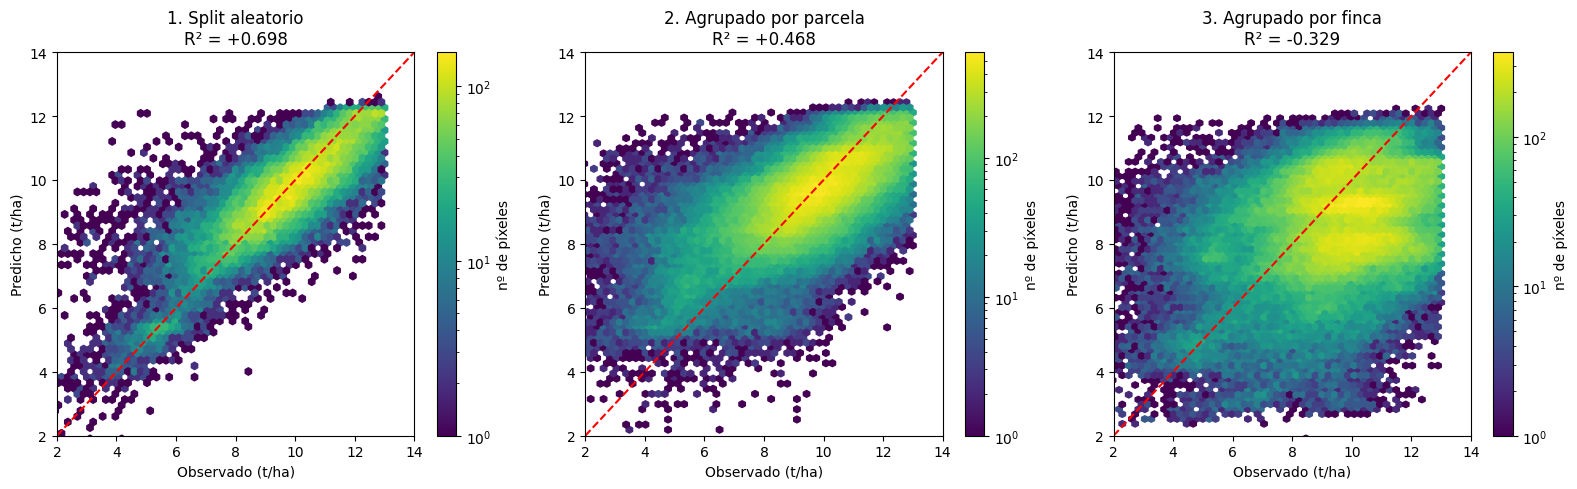

In [14]:
fig, axs = plt.subplots(1, 3, figsize=(16, 5))

casos = [
    ("1. Split aleatorio", y_te, mod.predict(X_te)),
    ("2. Agrupado por parcela", y, pred_p),
    ("3. Agrupado por finca", y, pred_f),
]

for ax, (titulo, obs, pred) in zip(axs, casos):
    hb = ax.hexbin(obs, pred, gridsize=60, cmap="viridis", mincnt=1, bins="log")
    lim = [2, 14]
    ax.plot(lim, lim, "r--", lw=1.5)
    ax.set_xlim(lim); ax.set_ylim(lim)
    ax.set_xlabel("Observado (t/ha)"); ax.set_ylabel("Predicho (t/ha)")
    ax.set_title(f"{titulo}\nR² = {r2_score(obs, pred):+.3f}")
    plt.colorbar(hb, ax=ax, label="nº de píxeles")

plt.tight_layout(); plt.show()

In [15]:
# X_nan = datos.drop(columns=["rendimiento", "parcela", "fila", "col"])
# y_nan = datos["rendimiento"]
# parcela_g_nan = datos["parcela"]
# finca_g_nan = datos["parcela"].str.split("_").str[:3].str.join("_")

# mod =  LGBMRegressor(
#         n_estimators=300, learning_rate=0.05, max_depth=6,
#         subsample=0.8, colsample_bytree=0.8, min_child_samples=20,
#         n_jobs=-1, random_state=42, verbose=-1)

# # --- 1. split aleatorio ---
# X_tr_nan, X_te_nan, y_tr_nan, y_te_nan = train_test_split(X_nan, y_nan, test_size=0.2, random_state=42)
# mod.fit(X_tr_nan, y_tr_nan)
# metricas("1. SPLIT ALEATORIO (píxeles mezclados)", y_te_nan, mod.predict(X_te_nan))

# # --- 2. agrupado por parcela ---
# cv_nan = GroupKFold(n_splits=5)
# pred_p_nan = cross_val_predict(mod, X_nan, y_nan, groups=parcela_g_nan, cv=cv_nan, n_jobs=-1)
# metricas("2. AGRUPADO POR PARCELA", y_nan, pred_p_nan)

# # --- 3. agrupado por finca ---
# pred_f_nan = cross_val_predict(mod, X_nan, y_nan, groups=finca_g_nan, cv=cv_nan, n_jobs=-1)
# metricas("3. AGRUPADO POR FINCA", y_nan, pred_f_nan)

# print(f"\nFincas: {finca_g_nan.nunique()} | Parcelas: {parcela_g_nan.nunique()}")
# print(f"Caída de R² (parcela → finca): {r2_score(y_nan, pred_p_nan) - r2_score(y_nan, pred_f_nan):.3f}")

## 8. Diagnóstico de la memorización

In [16]:
resumen = pd.DataFrame({
    "pixeles": finca_g.value_counts(),
    "porcentaje": (100 * finca_g.value_counts(normalize=True)).round(1),
    "parcelas": datos_modelo.groupby(finca_g)["parcela"].nunique(),
    "rend_medio": datos_modelo.groupby(finca_g)["rendimiento"].mean().round(2),
})
print(resumen.sort_values("pixeles", ascending=False).to_string())

                    pixeles  porcentaje  parcelas  rend_medio
parcela                                                      
Germany_DUP3_farm2    69426        46.9        88        9.90
Germany_DUP3_farm1    57162        38.6        22        9.64
Germany_DUP3_farm5     9392         6.3         3        9.04
Germany_DUP3_farm4     5742         3.9         3        8.73
Germany_DUP3_farm3     3739         2.5         2        5.20
Germany_DUP3_farm6     2513         1.7         2        6.02


In [17]:
X_cols = [c for c in datos_modelo.columns
          if c not in ["rendimiento", "parcela", "fila", "col"]]

variacion = datos_modelo.groupby("parcela")[X_cols].std().mean()
constantes = variacion[variacion < 1e-9].index.tolist()

print(f"Features totales:    {len(X_cols)}")
print(f"Constantes en parcela: {len(constantes)} ({100*len(constantes)/len(X_cols):.0f}%)")
print("\nLas constantes son:")
print(constantes)

Features totales:    71
Constantes en parcela: 30 (42%)

Las constantes son:
['tmax_v3', 'tmin_v3', 'tmed_v3', 'prec_v3', 'dias_v3', 'tmax_v4', 'tmin_v4', 'tmed_v4', 'prec_v4', 'dias_v4', 'tmax_v5', 'tmin_v5', 'tmed_v5', 'prec_v5', 'dias_v5', 'tmax_v6', 'tmin_v6', 'tmed_v6', 'prec_v6', 'dias_v6', 'tmax_v7', 'tmin_v7', 'tmed_v7', 'prec_v7', 'dias_v7', 'tmax_v8', 'tmin_v8', 'tmed_v8', 'prec_v8', 'dias_v8']


In [18]:
mod.fit(X, y)
imp = pd.Series(mod.feature_importances_, index=X.columns).sort_values(ascending=False)

print("Top 15:")
for nombre, valor in imp.head(15).items():
    marca = " ← CONSTANTE" if nombre in constantes else ""
    print(f"  {nombre:20s} {valor:8.1f}{marca}")

print(f"\nPeso de las constantes: {100*imp[constantes].sum()/imp.sum():.1f}%")

Top 15:
  dem                     429.0
  ndwi_v7                 289.0
  ndwi_v6                 281.0
  ndwi_v8                 270.0
  evi_v8                  255.0
  savi_v7                 233.0
  ndvi_v8                 209.0
  ndre_v5                 190.0
  evi_v7                  189.0
  ndvi_v6                 182.0
  gndvi_v6                182.0
  ndre_v7                 179.0
  evi_v4                  165.0
  ndwi_v5                 165.0
  ndwi_v3                 162.0

Peso de las constantes: 26.0%


In [19]:
print(datos_modelo.groupby("parcela")["dem"].std().describe())
print("\nElevación media por finca:")
print(datos_modelo.groupby(finca_g)["dem"].mean().round(1))

count    120.000000
mean       3.929143
std        2.622837
min        0.613220
25%        2.023477
50%        3.205649
75%        5.480256
max       13.414508
Name: dem, dtype: float64

Elevación media por finca:
parcela
Germany_DUP3_farm1    121.2
Germany_DUP3_farm2    208.1
Germany_DUP3_farm3    113.3
Germany_DUP3_farm4    103.9
Germany_DUP3_farm5     66.5
Germany_DUP3_farm6    178.6
Name: dem, dtype: float64


In [20]:
quitar = constantes + ["dem"]       # solo la elevación
X_sin = X.drop(columns=quitar)
print("="*62)
print("SIN CLIMA NI ELEVACIÓN · LightGBM")
print(f"{X.shape[1]} features → {X_sin.shape[1]} ({len(quitar)} eliminadas)")
print(f"{len(datos_modelo)} píxeles | {parcela_g.nunique()} parcelas | {finca_g.nunique()} fincas")
print("="*62)

cv = GroupKFold(n_splits=5)

# --- agrupado por parcela ---
pred_p_sin = cross_val_predict(mod, X_sin, y, groups=parcela_g, cv=cv, n_jobs=-1)
metricas("AGRUPADO POR PARCELA", y, pred_p_sin)

# --- agrupado por finca ---
pred_f_sin = cross_val_predict(mod, X_sin, y, groups=finca_g, cv=cv, n_jobs=-1)
metricas("AGRUPADO POR FINCA", y, pred_f_sin)

print("\n" + "-"*62)
print(f"Caída parcela → finca: {r2_score(y, pred_p_sin) - r2_score(y, pred_f_sin):.3f}")
print(f"Comparación por finca:  con todo {r2_score(y, pred_f):+.3f}  |  "
      f"sin identificadoras {r2_score(y, pred_f_sin):+.3f}")
print("-"*62)

SIN CLIMA NI ELEVACIÓN · LightGBM
71 features → 40 (31 eliminadas)
147974 píxeles | 120 parcelas | 6 fincas

AGRUPADO POR PARCELA
  R²      +0.424
  MAE     1.14 t/ha
  RMSE    1.50 t/ha
  r Pearson +0.652
  sesgo   +0.04 t/ha

AGRUPADO POR FINCA
  R²      +0.052
  MAE     1.55 t/ha
  RMSE    1.93 t/ha
  r Pearson +0.406
  sesgo   -0.29 t/ha

--------------------------------------------------------------
Caída parcela → finca: 0.373
Comparación por finca:  con todo -0.329  |  sin identificadoras +0.052
--------------------------------------------------------------


### Conclusiones del diagnóstico

La evaluación del modelo con tres criterios de partición revela un
comportamiento característico de la memorización. Con una partición
aleatoria de píxeles el modelo alcanza un R² de 0,70, pero este valor
carece de validez: píxeles de un mismo campo quedan repartidos entre
entrenamiento y prueba, de modo que el modelo evalúa campos que ya ha
visto. Al agrupar por parcela el rendimiento desciende a 0,47, y al
agrupar por explotación agrícola se hunde hasta −0,33, por debajo del
baseline de predecir la media. La caída de 0,80 entre ambos criterios
mide directamente cuánto del aparente acierto procedía de reconocer la
finca en lugar de interpretar la señal del cultivo.

El análisis de las variables explicativas identifica el mecanismo. De
las 71 variables, 30 son estrictamente constantes dentro de cada
parcela: las agregaciones climáticas por ventana térmica, que proceden
de una única serie por campo. A ellas se suma la elevación, que varía
3,9 m de media dentro de una parcela frente a los 140 m que separan las
explotaciones, y que resulta ser la variable más influyente del modelo.
Ambos conjuntos operan como identificadores: permiten reconocer la
explotación y asignarle su nivel medio de rendimiento sin necesidad de
interpretar el estado del cultivo.

La estructura de la muestra agrava el problema. Las 120 parcelas
pertenecen a solo seis explotaciones, dos de las cuales concentran el
86% de los píxeles, y su rendimiento medio oscila entre 5,2 y 9,9 t/ha.
Esa diferencia de nivel responde a variedad, fertilización y manejo,
información ausente del conjunto de datos y no inferible a partir de
la reflectancia.

La eliminación de las variables identificadoras confirma el
diagnóstico sin resolverlo. Reducido el modelo a 40 variables, el R²
agrupado por explotación pasa de −0,33 a +0,05 y el sesgo se reduce de
−0,94 a −0,29 t/ha, pero el resultado apenas supera el baseline. La
mejora demuestra que esas variables alimentaban la memorización; su
insuficiencia demuestra que el problema no reside en la selección de
variables sino en la formulación del objetivo.

La descomposición de la varianza del rendimiento orienta la
alternativa: el 43% corresponde a diferencias entre parcelas y el 60%
a variación espacial interna. El primer componente depende de
información no disponible y cuenta con tantas observaciones como
parcelas; el segundo queda registrado en la serie temporal de imágenes
con miles de observaciones por campo. Se reformula en consecuencia el
objetivo hacia el rendimiento relativo intra-parcela, expresando cada
píxel como proporción respecto a la mediana de su campo. La
transformación elimina por construcción las variables constantes, que
al restarles la mediana de su parcela se anulan, y centra el
aprendizaje sobre el componente que los datos sí permiten explicar.

## 9. Modelo relativo intra-parcela

In [21]:
cols_id = ["rendimiento", "parcela", "fila", "col"]
cols_X = [c for c in datos_modelo.columns if c not in cols_id]

rel = datos_modelo.copy()

# objetivo: proporción respecto a la mediana de su parcela
rel["rend_rel"] = (rel["rendimiento"] /
                   rel.groupby("parcela")["rendimiento"].transform("median"))

# features: desviación respecto a la mediana de su parcela
rel[cols_X] = rel[cols_X] - rel.groupby("parcela")[cols_X].transform("median")

# las constantes quedan a cero y se eliminan solas
varia = rel[cols_X].std()
cols_utiles = varia[varia > 1e-9].index.tolist()

print(f"Features: {len(cols_X)} → {len(cols_utiles)} "
      f"({len(cols_X)-len(cols_utiles)} se anularon al centrar)")

X_rel = rel[cols_utiles]
y_rel = rel["rend_rel"]

print(f"\nObjetivo relativo: mediana {y_rel.median():.3f}, "
      f"rango [{y_rel.quantile(0.01):.2f}, {y_rel.quantile(0.99):.2f}]")

# --- validación en los tres niveles ---
print("\n" + "="*62)
print("RENDIMIENTO RELATIVO · LightGBM")
print(f"{len(X_rel)} píxeles | {parcela_g.nunique()} parcelas | {finca_g.nunique()} fincas")
print("="*62)

cv = GroupKFold(n_splits=5)

# --- 1. split aleatorio ---
Xr_tr, Xr_te, yr_tr, yr_te = train_test_split(X_rel, y_rel, test_size=0.2, random_state=42)
mod.fit(Xr_tr, yr_tr)
metricas("1. SPLIT ALEATORIO (píxeles mezclados)", yr_te, mod.predict(Xr_te))

# --- 2. agrupado por parcela ---
pred_p_rel = cross_val_predict(mod, X_rel, y_rel, groups=parcela_g, cv=cv, n_jobs=-1)
metricas("2. AGRUPADO POR PARCELA", y_rel, pred_p_rel)

# --- 3. agrupado por finca ---
pred_rel = cross_val_predict(mod, X_rel, y_rel, groups=finca_g, cv=cv, n_jobs=-1)
metricas("3. AGRUPADO POR FINCA", y_rel, pred_rel)

print("\n" + "-"*62)
print(f"Caída parcela → finca: {r2_score(y_rel, pred_p_rel) - r2_score(y_rel, pred_rel):.3f}")
print("-"*62)

Features: 71 → 41 (30 se anularon al centrar)

Objetivo relativo: mediana 1.000, rango [0.45, 1.31]

RENDIMIENTO RELATIVO · LightGBM
147974 píxeles | 120 parcelas | 6 fincas

1. SPLIT ALEATORIO (píxeles mezclados)
  R²      +0.437
  MAE     0.08 t/ha
  RMSE    0.12 t/ha
  r Pearson +0.662
  sesgo   -0.00 t/ha

2. AGRUPADO POR PARCELA
  R²      +0.333
  MAE     0.09 t/ha
  RMSE    0.13 t/ha
  r Pearson +0.577
  sesgo   -0.00 t/ha

3. AGRUPADO POR FINCA
  R²      +0.271
  MAE     0.10 t/ha
  RMSE    0.13 t/ha
  r Pearson +0.525
  sesgo   -0.00 t/ha

--------------------------------------------------------------
Caída parcela → finca: 0.062
--------------------------------------------------------------


## 10. Validación del modelo relativo

In [22]:
rel["pred"] = pred_rel
rhos = rel.groupby("parcela")[["rend_rel", "pred"]].apply(
    lambda g: spearmanr(g["rend_rel"], g["pred"])[0]).sort_values()

print(f"Spearman intra-parcela:")
print(f"  mediana              {rhos.median():+.3f}")
print(f"  parcelas con rho>0.3 {100*(rhos > 0.3).mean():.0f}%")
print(f"  parcelas con rho<0   {100*(rhos < 0).mean():.0f}%")

Spearman intra-parcela:
  mediana              +0.506
  parcelas con rho>0.3 92%
  parcelas con rho<0   1%


In [23]:
tam = rel.groupby("parcela").size()
print(pd.DataFrame({"pixeles": tam, "rho": rhos}).sort_values("rho").head(10))

                                        pixeles       rho
parcela                                                  
Germany_DUP3_farm1_field32_wheat_2017        23 -0.441700
Germany_DUP3_farm2_field154_wheat_2021      279  0.024091
Germany_DUP3_farm1_field37_wheat_2017       125  0.126009
Germany_DUP3_farm1_field36_wheat_2017       131  0.245684
Germany_DUP3_farm2_field100_wheat_2019     1044  0.248458
Germany_DUP3_farm2_field87_wheat_2018       704  0.262561
Germany_DUP3_farm2_field162_wheat_2019      530  0.265863
Germany_DUP3_farm2_field136_wheat_2019      365  0.286221
Germany_DUP3_farm2_field101_wheat_2020      996  0.290375
Germany_DUP3_farm2_field121_wheat_2019      786  0.296485


In [24]:
rhos_ok = rhos[tam >= 500]
print(f"Parcelas con >500 píxeles: {len(rhos_ok)} de {len(rhos)}")
print(f"  mediana  {rhos_ok.median():+.3f}")
print(f"  rho>0.3  {100*(rhos_ok > 0.3).mean():.0f}%")
print(f"  rho<0    {100*(rhos_ok < 0).mean():.0f}%")

Parcelas con >500 píxeles: 94 de 120
  mediana  +0.511
  rho>0.3  95%
  rho<0    0%


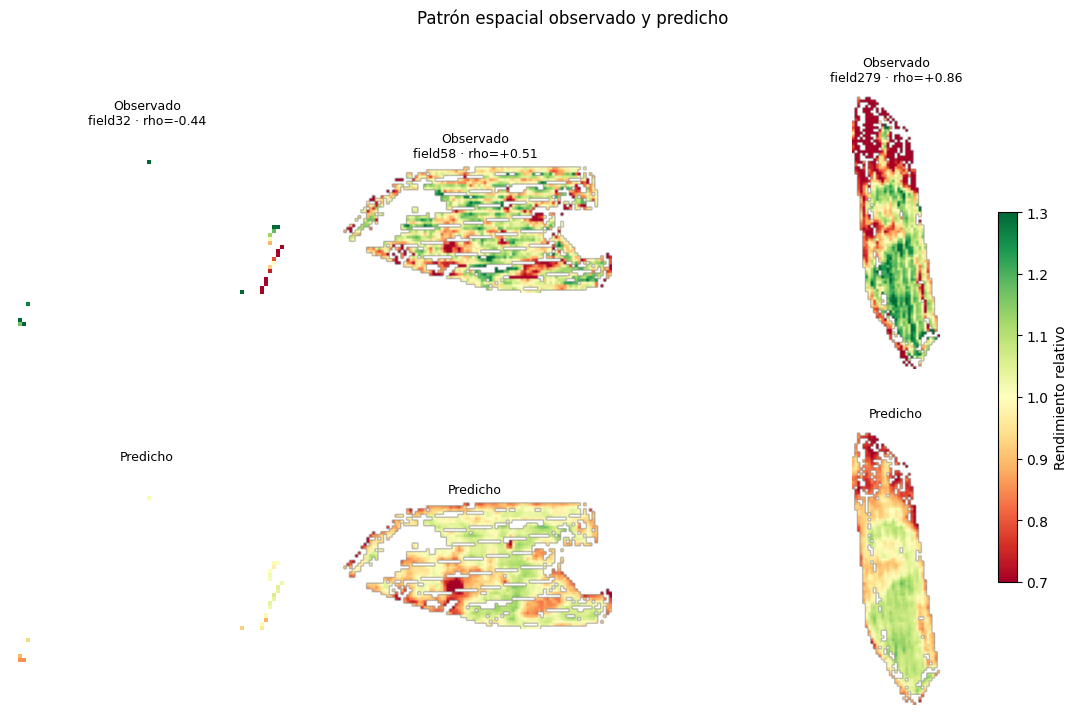

In [25]:
# elijo tres casos: el peor, la mediana y el mejor
casos = [rhos.index[0], rhos.index[len(rhos)//2], rhos.index[-1]]

fig, axs = plt.subplots(2, 3, figsize=(15, 8))

for j, p in enumerate(casos):
    g = rel[rel["parcela"] == p]
    alto, ancho = g["fila"].max()+1, g["col"].max()+1

    for i, col in enumerate(["rend_rel", "pred"]):
        mapa = np.full((alto, ancho), np.nan)
        mapa[g["fila"], g["col"]] = g[col]
        im = axs[i, j].imshow(mapa, cmap="RdYlGn", vmin=0.7, vmax=1.3)
        axs[i, j].axis("off")
        axs[i, j].set_title(("Observado" if i == 0 else "Predicho") +
                            (f"\n{p.split('_')[3]} · rho={rhos[p]:+.2f}" if i == 0 else ""),
                            fontsize=9)

fig.colorbar(im, ax=axs, shrink=0.6, label="Rendimiento relativo")
fig.suptitle("Patrón espacial observado y predicho", fontsize=12)
plt.show()

Top 15 por importancia de permutación:
  ndwi_v7           0.0940
  ndre_v8           0.0522
  ndwi_v6           0.0463
  ndre_v7           0.0444
  ndwi_v8           0.0397
  ndvi_v7           0.0353
  evi_v8            0.0353
  evi_v7            0.0301
  ndwi_v5           0.0223
  dem               0.0215
  ndvi_v8           0.0178
  orient_sur        0.0153
  savi_v8           0.0145
  twi_propio        0.0141
  gndvi_v7          0.0138


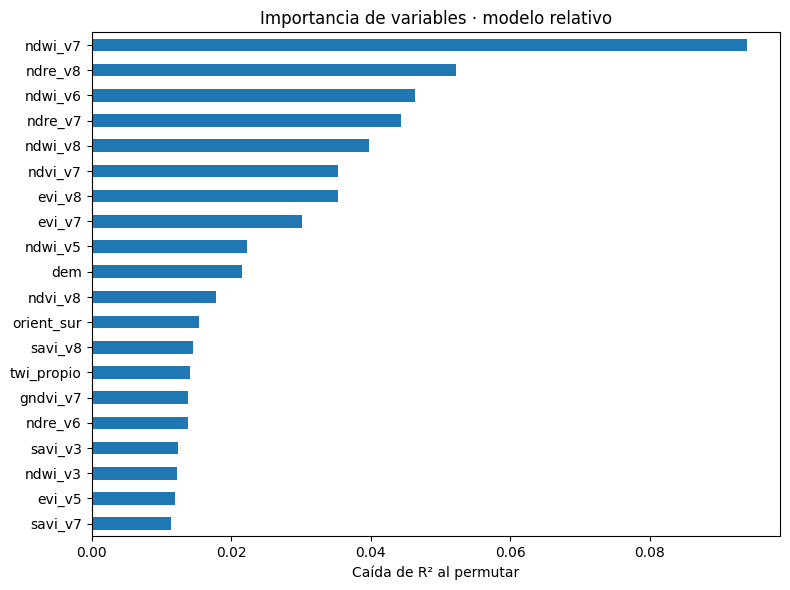

In [26]:
# entreno sobre una muestra para que no tarde una eternidad
muestra = rel.sample(min(40000, len(rel)), random_state=42)
Xm = muestra[cols_utiles]
ym = muestra["rend_rel"]

mod.fit(Xm, ym)
perm = permutation_importance(mod, Xm, ym, n_repeats=5,
                              random_state=42, n_jobs=-1, scoring="r2")

imp = pd.Series(perm.importances_mean, index=cols_utiles).sort_values(ascending=False)

print("Top 15 por importancia de permutación:")
for n, v in imp.head(15).items():
    print(f"  {n:16s} {v:7.4f}")

plt.figure(figsize=(8, 6))
imp.head(20).iloc[::-1].plot.barh()
plt.xlabel("Caída de R² al permutar")
plt.title("Importancia de variables · modelo relativo")
plt.tight_layout(); plt.show()